In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/cleaned_loan_dataset.csv')

In [5]:
df.head()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [6]:
df.tail()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,480,Male,Yes,2,Graduate,No,2947,1603.0,10,360,1,Urban,N
610,525,Male,No,0,Graduate,No,4680,2087.0,15,360,1,Semiurban,N
611,551,Male,Yes,2,Graduate,Yes,6633,0.0,25,360,0,Rural,N
612,552,Male,Yes,1,Not Graduate,No,2492,2375.0,30,360,1,Rural,Y
613,606,Male,Yes,0,Not Graduate,No,2400,3800.0,25,180,1,Urban,N


In [7]:
df.shape

(614, 13)

In [8]:
df.columns

Index(['Customer_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Applicant_Income', 'Coapplicant_Income',
       'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status'],
      dtype='object')

In [9]:
df.dtypes

,0
Customer_ID,int64
Gender,object
Married,object
Dependents,int64
Education,object
Self_Employed,object
Applicant_Income,int64
Coapplicant_Income,float64
Loan_Amount,int64
Loan_Amount_Term,int64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         614 non-null    int64  
 1   Gender              614 non-null    object 
 2   Married             614 non-null    object 
 3   Dependents          614 non-null    int64  
 4   Education           614 non-null    object 
 5   Self_Employed       614 non-null    object 
 6   Applicant_Income    614 non-null    int64  
 7   Coapplicant_Income  614 non-null    float64
 8   Loan_Amount         614 non-null    int64  
 9   Loan_Amount_Term    614 non-null    int64  
 10  Credit_History      614 non-null    int64  
 11  Property_Area       614 non-null    object 
 12  Loan_Status         614 non-null    object 
dtypes: float64(1), int64(6), object(6)
memory usage: 62.5+ KB


In [11]:
df.describe()

,Customer_ID,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,307.500000,0.856678,5403.459283,1621.245798,142.022801,338.892508,0.850163
std,177.390811,1.216651,6109.041673,2926.248369,87.083089,69.716355,0.357203
min,1.000000,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000
25%,154.250000,0.000000,2877.500000,0.000000,98.000000,360.000000,1.000000
50%,307.500000,0.000000,3812.500000,1188.500000,125.000000,360.000000,1.000000
75%,460.750000,2.000000,5795.000000,2297.250000,164.750000,360.000000,1.000000
max,614.000000,4.000000,81000.000000,41667.000000,700.000000,480.000000,1.000000


In [12]:
df.isnull().sum()

,0
Customer_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Applicant_Income,0
Coapplicant_Income,0
Loan_Amount,0
Loan_Amount_Term,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["TotalIncome"] = df["Applicant_Income"] + df["Coapplicant_Income"]

In [15]:
df[["Applicant_Income", "Coapplicant_Income", "TotalIncome"]].head(10)

,Applicant_Income,Coapplicant_Income,TotalIncome
0,2378,0.0,2378.0
1,1299,1086.0,2385.0
2,3620,0.0,3620.0
3,3459,0.0,3459.0
4,5468,1032.0,6500.0
5,1538,1425.0,2963.0
6,3237,0.0,3237.0
7,1442,0.0,1442.0
8,3166,0.0,3166.0
9,13262,0.0,13262.0


In [16]:
df["TotalIncome"].describe()

,TotalIncome
count,614.000000
mean,7024.705081
std,6458.663872
min,1442.000000
25%,4166.000000
50%,5416.500000
75%,7521.750000
max,81000.000000


In [17]:
(df["TotalIncome"] == df["Applicant_Income"] + df["Coapplicant_Income"]).all()

np.True_

In [18]:
df.shape

(614, 14)

In [19]:
df["LoanIncomeRatio"] = (df["Loan_Amount"] * 1000) / df["TotalIncome"]

In [20]:
df[["Loan_Amount", "TotalIncome", "LoanIncomeRatio"]].head(10)

,Loan_Amount,TotalIncome,LoanIncomeRatio
0,9,2378.0,3.784693
1,17,2385.0,7.127883
2,25,3620.0,6.906077
3,25,3459.0,7.227522
4,26,6500.0,4.000000
5,30,2963.0,10.124873
6,30,3237.0,9.267841
7,35,1442.0,24.271845
8,36,3166.0,11.370815
9,40,13262.0,3.016136


In [21]:
df["LoanIncomeRatio"].describe()

,LoanIncomeRatio
count,614.000000
mean,23.090338
std,8.882430
min,1.209658
25%,18.446698
50%,23.816614
75%,28.030267
max,82.711645


In [22]:
((df["LoanIncomeRatio"] == (df["Loan_Amount"] * 1000) / df["TotalIncome"])).all()

np.True_

In [23]:
df["IncomeCategory"] = pd.cut(
    df["TotalIncome"],
    bins=[0, 5000, 15000, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

In [24]:
df[["TotalIncome", "IncomeCategory"]].head(15)

,TotalIncome,IncomeCategory
0,2378.0,Low
1,2385.0,Low
2,3620.0,Low
3,3459.0,Low
4,6500.0,Medium
5,2963.0,Low
6,3237.0,Low
7,1442.0,Low
8,3166.0,Low
9,13262.0,Medium


In [25]:
df["IncomeCategory"].value_counts()

,count
IncomeCategory,
Medium,308
Low,270
High,36


In [26]:
df["IncomeCategory"].value_counts(normalize=True) * 100

,proportion
IncomeCategory,
Medium,50.162866
Low,43.973941
High,5.863192


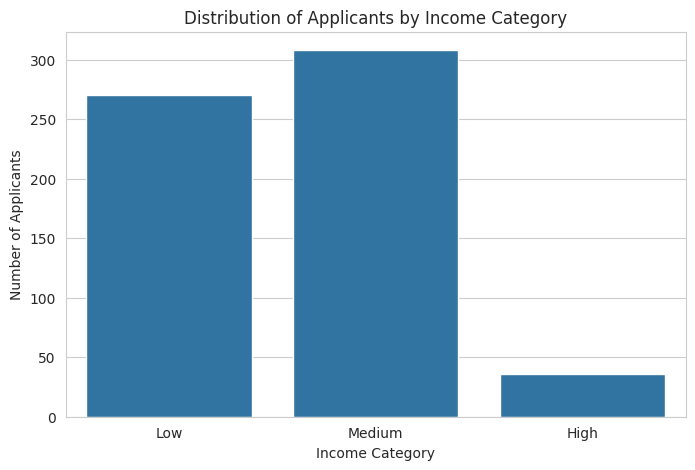

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="IncomeCategory")

plt.title("Distribution of Applicants by Income Category")
plt.xlabel("Income Category")
plt.ylabel("Number of Applicants")

plt.show()

In [28]:
df["IncomeCategory"].isnull().sum()

np.int64(0)

In [29]:
df.dtypes

,0
Customer_ID,int64
Gender,object
Married,object
Dependents,int64
Education,object
Self_Employed,object
Applicant_Income,int64
Coapplicant_Income,float64
Loan_Amount,int64
Loan_Amount_Term,int64


In [30]:
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Customer_ID', 'Dependents', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'LoanIncomeRatio']

Categorical Features:
['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status', 'IncomeCategory']


In [31]:
numerical_features = [col for col in numerical_features if col not in ["Customer_ID", "Loan_Status"]]

categorical_features = [col for col in categorical_features if col not in ["Customer_ID", "Loan_Status"]]

print("Final Numerical Features:")
print(numerical_features)

print("\nFinal Categorical Features:")
print(categorical_features)

Final Numerical Features:
['Dependents', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'LoanIncomeRatio']

Final Categorical Features:
['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area', 'IncomeCategory']


In [32]:
X = df[numerical_features + categorical_features].copy()

y = df["Loan_Status"].copy()

In [33]:
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (614, 14)
Target Variable Shape: (614,)


In [34]:
X.head()

,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,TotalIncome,LoanIncomeRatio,Gender,Married,Education,Self_Employed,Property_Area,IncomeCategory
0,0,2378,0.0,9,360,1,2378.0,3.784693,Female,No,Graduate,No,Urban,Low
1,2,1299,1086.0,17,120,1,2385.0,7.127883,Male,Yes,Graduate,No,Urban,Low
2,0,3620,0.0,25,120,1,3620.0,6.906077,Male,No,Not Graduate,No,Semiurban,Low
3,0,3459,0.0,25,120,1,3459.0,7.227522,Male,Yes,Graduate,Yes,Semiurban,Low
4,1,5468,1032.0,26,360,1,6500.0,4.000000,Male,Yes,Graduate,No,Semiurban,Medium


In [35]:
y.head()

,Loan_Status
0,N
1,Y
2,Y
3,Y
4,Y


In [36]:
print(y.value_counts())

print("\nTarget Distribution in Percentage:")
print(y.value_counts(normalize=True) * 100)

Loan_Status
Y    422
N    192
Name: count, dtype: int64

Target Distribution in Percentage:
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


In [37]:
for col in categorical_features:
    print(col)
    print(X[col].unique())
    print()

Gender
['Female' 'Male']

Married
['No' 'Yes']

Education
['Graduate' 'Not Graduate']

Self_Employed
['No' 'Yes']

Property_Area
['Urban' 'Semiurban' 'Rural']

IncomeCategory
['Low', 'Medium', 'High']
Categories (3, object): ['Low' < 'Medium' < 'High']



In [38]:
X["Gender"] = X["Gender"].map({"Female": 0, "Male": 1})

X["Married"] = X["Married"].map({"No": 0, "Yes": 1})

X["Education"] = X["Education"].map({"Not Graduate": 0, "Graduate": 1})

X["Self_Employed"] = X["Self_Employed"].map({"No": 0, "Yes": 1})

In [39]:
print(X[["Gender", "Married", "Education", "Self_Employed"]].head(10))

print("\nUnique values after encoding:")

for col in ["Gender", "Married", "Education", "Self_Employed"]:
    print(col, X[col].unique())

   Gender  Married  Education  Self_Employed
0       0        0          1              0
1       1        1          1              0
2       1        0          0              0
3       1        1          1              1
4       1        1          1              0
5       1        1          1              0
6       0        0          1              0
7       1        0          0              0
8       0        1          1              0
9       0        0          1              0

Unique values after encoding:
Gender [0 1]
Married [0 1]
Education [1 0]
Self_Employed [0 1]


In [40]:
X["IncomeCategory"] = X["IncomeCategory"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})

In [41]:
print(X["IncomeCategory"].head(10))

print("\nUnique values:")
print(X["IncomeCategory"].unique())

0    0
1    0
2    0
3    0
4    1
5    0
6    0
7    0
8    0
9    1
Name: IncomeCategory, dtype: category
Categories (3, int64): [0 < 1 < 2]

Unique values:
[0, 1, 2]
Categories (3, int64): [0 < 1 < 2]


In [42]:
X = pd.get_dummies(X, columns=["Property_Area"], dtype=int)

In [43]:
print(X.head())

print("\nNew Property Area Columns:")
print(X[["Property_Area_Rural", "Property_Area_Semiurban", "Property_Area_Urban"]].head(10))

   Dependents  Applicant_Income  Coapplicant_Income  Loan_Amount  \
0           0              2378                 0.0            9   
1           2              1299              1086.0           17   
2           0              3620                 0.0           25   
3           0              3459                 0.0           25   
4           1              5468              1032.0           26   

   Loan_Amount_Term  Credit_History  TotalIncome  LoanIncomeRatio  Gender  \
0               360               1       2378.0         3.784693       0   
1               120               1       2385.0         7.127883       1   
2               120               1       3620.0         6.906077       1   
3               120               1       3459.0         7.227522       1   
4               360               1       6500.0         4.000000       1   

   Married  Education  Self_Employed IncomeCategory  Property_Area_Rural  \
0        0          1              0              0 

In [44]:
print(X.dtypes)

Dependents                    int64
Applicant_Income              int64
Coapplicant_Income          float64
Loan_Amount                   int64
Loan_Amount_Term              int64
Credit_History                int64
TotalIncome                 float64
LoanIncomeRatio             float64
Gender                        int64
Married                       int64
Education                     int64
Self_Employed                 int64
IncomeCategory             category
Property_Area_Rural           int64
Property_Area_Semiurban       int64
Property_Area_Urban           int64
dtype: object


In [45]:
X["IncomeCategory"] = X["IncomeCategory"].astype(int)

In [46]:
print(X.dtypes)

Dependents                   int64
Applicant_Income             int64
Coapplicant_Income         float64
Loan_Amount                  int64
Loan_Amount_Term             int64
Credit_History               int64
TotalIncome                float64
LoanIncomeRatio            float64
Gender                       int64
Married                      int64
Education                    int64
Self_Employed                int64
IncomeCategory               int64
Property_Area_Rural          int64
Property_Area_Semiurban      int64
Property_Area_Urban          int64
dtype: object


In [47]:
print("Missing values in X:", X.isnull().sum().sum())

print("\nMissing values in each column:")
print(X.isnull().sum())

Missing values in X: 0

Missing values in each column:
Dependents                 0
Applicant_Income           0
Coapplicant_Income         0
Loan_Amount                0
Loan_Amount_Term           0
Credit_History             0
TotalIncome                0
LoanIncomeRatio            0
Gender                     0
Married                    0
Education                  0
Self_Employed              0
IncomeCategory             0
Property_Area_Rural        0
Property_Area_Semiurban    0
Property_Area_Urban        0
dtype: int64


In [48]:
print("Final X Shape:", X.shape)

print("\nFinal Encoded Features:")
print(X.head())

Final X Shape: (614, 16)

Final Encoded Features:
   Dependents  Applicant_Income  Coapplicant_Income  Loan_Amount  \
0           0              2378                 0.0            9   
1           2              1299              1086.0           17   
2           0              3620                 0.0           25   
3           0              3459                 0.0           25   
4           1              5468              1032.0           26   

   Loan_Amount_Term  Credit_History  TotalIncome  LoanIncomeRatio  Gender  \
0               360               1       2378.0         3.784693       0   
1               120               1       2385.0         7.127883       1   
2               120               1       3620.0         6.906077       1   
3               120               1       3459.0         7.227522       1   
4               360               1       6500.0         4.000000       1   

   Married  Education  Self_Employed  IncomeCategory  Property_Area_Rural  \
0

In [49]:
import numpy as np

np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

In [50]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (491, 16)
Testing Features: (123, 16)
Training Target: (491,)
Testing Target: (123,)


In [51]:
scaling_features = [
    "Applicant_Income",
    "Coapplicant_Income",
    "Loan_Amount",
    "Loan_Amount_Term",
    "TotalIncome",
    "LoanIncomeRatio"
]

print(scaling_features)

['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'TotalIncome', 'LoanIncomeRatio']


In [52]:
train_mean = X_train[scaling_features].mean()

train_std = X_train[scaling_features].std()

print("Training Mean:")
print(train_mean)

print("\nTraining Standard Deviation:")
print(train_std)

Training Mean:
Applicant_Income      5517.769857
Coapplicant_Income    1636.152994
Loan_Amount            143.380855
Loan_Amount_Term       339.348269
TotalIncome           7153.922851
LoanIncomeRatio         23.235360
dtype: float64

Training Standard Deviation:
Applicant_Income      6648.385929
Coapplicant_Income    3119.761871
Loan_Amount             90.233527
Loan_Amount_Term        67.680152
TotalIncome           6988.997669
LoanIncomeRatio          9.062935
dtype: float64


In [53]:
X_train[scaling_features] = (
    X_train[scaling_features] - train_mean
) / train_std

X_test[scaling_features] = (
    X_test[scaling_features] - train_mean
) / train_std

In [54]:
print("Training Data After Scaling:")
print(X_train[scaling_features].head())

print("\nTraining Mean After Scaling:")
print(X_train[scaling_features].mean())

print("\nTraining Standard Deviation After Scaling:")
print(X_train[scaling_features].std())

Training Data After Scaling:
     Applicant_Income  Coapplicant_Income  Loan_Amount  Loan_Amount_Term  \
350         -0.175045           -0.524448    -0.081797          0.305137   
377         -0.325007            0.391968     0.006862          0.305137   
163         -0.455264            0.133936    -0.436433          0.305137   
609         -0.386676           -0.010627    -1.478174          0.305137   
132         -0.388481           -0.524448    -0.502927          0.305137   

     TotalIncome  LoanIncomeRatio  
350    -0.400619         0.882748  
377    -0.134200        -0.007651  
163    -0.373290        -0.038958  
609    -0.372575        -2.321274  
132    -0.603652         1.120471  

Training Mean After Scaling:
Applicant_Income      4.160510e-17
Coapplicant_Income    2.532484e-17
Loan_Amount          -4.070064e-17
Loan_Amount_Term      3.075159e-17
TotalIncome          -7.778345e-17
LoanIncomeRatio      -3.011847e-16
dtype: float64

Training Standard Deviation After Scaling:

In [55]:
print("TRAINING AND TESTING DATA")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nMISSING VALUES")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_train:", y_train.isnull().sum())
print("y_test:", y_test.isnull().sum())

print("\nDATA TYPES")
print(X_train.dtypes.value_counts())

print("\nTARGET DISTRIBUTION IN TRAINING DATA")
print(y_train.value_counts())

print("\nTARGET DISTRIBUTION IN TESTING DATA")
print(y_test.value_counts())

TRAINING AND TESTING DATA
X_train: (491, 16)
X_test: (123, 16)
y_train: (491,)
y_test: (123,)

MISSING VALUES
X_train: 0
X_test: 0
y_train: 0
y_test: 0

DATA TYPES
int64      10
float64     6
Name: count, dtype: int64

TARGET DISTRIBUTION IN TRAINING DATA
Loan_Status
Y    338
N    153
Name: count, dtype: int64

TARGET DISTRIBUTION IN TESTING DATA
Loan_Status
Y    84
N    39
Name: count, dtype: int64


In [56]:
print("TRAINING DATA MEAN AFTER SCALING")
print(X_train[scaling_features].mean().round(4))

print("\nTRAINING DATA STANDARD DEVIATION AFTER SCALING")
print(X_train[scaling_features].std().round(4))

TRAINING DATA MEAN AFTER SCALING
Applicant_Income      0.0
Coapplicant_Income    0.0
Loan_Amount          -0.0
Loan_Amount_Term      0.0
TotalIncome          -0.0
LoanIncomeRatio      -0.0
dtype: float64

TRAINING DATA STANDARD DEVIATION AFTER SCALING
Applicant_Income      1.0
Coapplicant_Income    1.0
Loan_Amount           1.0
Loan_Amount_Term      1.0
TotalIncome           1.0
LoanIncomeRatio       1.0
dtype: float64


In [57]:
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("All four processed datasets saved successfully.")

All four processed datasets saved successfully.


In [58]:
import zipfile

with zipfile.ZipFile("Member4_Processed_Datasets.zip", "w") as zipf:
    zipf.write("X_train.csv")
    zipf.write("X_test.csv")
    zipf.write("y_train.csv")
    zipf.write("y_test.csv")

print("ZIP file created successfully.")

ZIP file created successfully.


In [59]:
X_processed = pd.concat([X_train, X_test]).sort_index()

y_processed = pd.concat([y_train, y_test]).sort_index()

loan_dataset_after_step_8 = X_processed.copy()

loan_dataset_after_step_8["Loan_Status"] = y_processed

loan_dataset_after_step_8.to_csv("loan_dataset_after_step_8.csv", index=False)

In [60]:
print(loan_dataset_after_step_8.shape)
print(loan_dataset_after_step_8.head())

(614, 17)
   Dependents  Applicant_Income  Coapplicant_Income  Loan_Amount  \
0           0         -0.472260           -0.524448    -1.489256   
1           2         -0.634555           -0.176345    -1.400598   
2           0         -0.285448           -0.524448    -1.311939   
3           0         -0.309665           -0.524448    -1.311939   
4           1         -0.007486           -0.193654    -1.300856   

   Loan_Amount_Term  Credit_History  TotalIncome  LoanIncomeRatio  Gender  \
0          0.305137               1    -0.683349        -2.146177       0   
1         -3.240954               1    -0.682347        -1.777292       1   
2         -3.240954               1    -0.505641        -1.801765       1   
3         -3.240954               1    -0.528677        -1.766297       1   
4          0.305137               1    -0.093565        -2.122421       1   

   Married  Education  Self_Employed  IncomeCategory  Property_Area_Rural  \
0        0          1              0     

In [61]:
from google.colab import files

files.download("loan_dataset_after_step_8.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>